# Лабораторная работа №2: Аугментация данных и устойчивость

Выполнила: Перминова Анастасия, группа М4221

In [2]:
from pathlib import Path
import sys
import subprocess
import re
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Image, Markdown

In [3]:
LAB_DIR = Path.cwd()

SCRIPTS_DIR = LAB_DIR / "scripts"
DATA_DIR = LAB_DIR / "data"
WAV_DIR = DATA_DIR / "wav"

OUTPUT_DIR = LAB_DIR / "outputs"
AUG_DIR = OUTPUT_DIR / "augmented"
FIG_DIR = OUTPUT_DIR / "figures"
RESULTS_DIR = OUTPUT_DIR / "results"

In [4]:
per_item = pd.read_csv(RESULTS_DIR / "per_item_results.csv")

aggregate = pd.read_csv(RESULTS_DIR / "aggregate_results.csv")

print("Размер per_item_results:", per_item.shape)
print("Размер aggregate_results:", aggregate.shape)

Размер per_item_results: (35, 13)
Размер aggregate_results: (7, 6)


In [5]:
display(per_item)

,item_id,condition,parameters,seed,reference_raw,reference_normalized,hypothesis_raw,hypothesis_normalized,wer,cer,audio_seconds,decode_seconds,rtf
0,1272-128104-0000,clean,{},17,MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CL...,mister quilter is the apostle of the middle cl...,Mr. Quilter is the apostle of the middle class...,mr quilter is the apostle of the middle classe...,0.058824,0.044944,5.855000,0.545764,0.093213
1,1272-128104-0000,noise_20db,"{""snr_db"": 20.0}",17,MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CL...,mister quilter is the apostle of the middle cl...,Mr. Quilter is the apostle of the middle class...,mr quilter is the apostle of the middle classe...,0.058824,0.044944,5.855000,0.520201,0.088847
2,1272-128104-0000,noise_10db,"{""snr_db"": 10.0}",17,MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CL...,mister quilter is the apostle of the middle cl...,Mr. Quilter is the apostle of the middle class...,mr quilter is the apostle of the middle classe...,0.058824,0.044944,5.855000,0.500123,0.085418
3,1272-128104-0000,noise_0db,"{""snr_db"": 0.0}",17,MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CL...,mister quilter is the apostle of the middle cl...,Mr. Closer is the apostle of the middle classe...,mr closer is the apostle of the middle classes...,0.411765,0.258427,5.855000,0.410962,0.070190
4,1272-128104-0000,reverb_room_a,"{""rir"": ""room_a""}",17,MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CL...,mister quilter is the apostle of the middle cl...,Mr. Quilter is the apostle of the middle class...,mr quilter is the apostle of the middle classe...,0.058824,0.044944,5.855000,0.439790,0.075114
5,1272-128104-0000,speed_0.9x,"{""speed_factor"": 0.9}",17,MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CL...,mister quilter is the apostle of the middle cl...,Mr. Quilter is the apostle of the middle class...,mr quilter is the apostle of the middle classe...,0.058824,0.044944,6.505562,0.470507,0.072324
6,1272-128104-0000,speed_1.1x,"{""speed_factor"": 1.1}",17,MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CL...,mister quilter is the apostle of the middle cl...,Mr. Quilter is the apostle of the middle class...,mr quilter is the apostle of the middle classe...,0.058824,0.044944,5.322750,0.396331,0.074460
7,1272-128104-0001,clean,{},17,NOR IS MISTER QUILTER'S MANNER LESS INTERESTIN...,nor is mister quilter's manner less interestin...,Nor is Mr. Quilter's manner less interesting t...,nor is mr quilter's manner less interesting th...,0.100000,0.063492,4.815000,0.436871,0.090731
8,1272-128104-0001,noise_20db,"{""snr_db"": 20.0}",17,NOR IS MISTER QUILTER'S MANNER LESS INTERESTIN...,nor is mister quilter's manner less interestin...,Nor is Mr. Coulter's manner less interesting t...,nor is mr coulter's manner less interesting th...,0.200000,0.111111,4.815000,0.480082,0.099706
9,1272-128104-0001,noise_10db,"{""snr_db"": 10.0}",17,NOR IS MISTER QUILTER'S MANNER LESS INTERESTIN...,nor is mister quilter's manner less interestin...,Nor is Mr. Colter's matter less interesting th...,nor is mr colter's matter less interesting tha...,0.300000,0.142857,4.815000,0.433528,0.090037


In [6]:
display(aggregate)

,condition,utterance_count,reference_word_count,mean_wer,mean_cer,mean_rtf
0,clean,5,82,0.083958,0.049979,0.091586
1,noise_0db,5,82,0.701564,0.394072,0.166293
2,noise_10db,5,82,0.148958,0.081784,0.098578
3,noise_20db,5,82,0.128958,0.070029,0.090446
4,reverb_room_a,5,82,0.112291,0.054824,0.108494
5,speed_0.9x,5,82,0.083958,0.047959,0.095157
6,speed_1.1x,5,82,0.067291,0.044574,0.108567


## Задание №1

Выберите пару аугментаций, и проанализируйте, как они влияют на сигнал. Какие два видимые изменения вы наблюдаете в волновой форме и/или log-Mel представлении?

In [7]:
PLOT_SCRIPT = SCRIPTS_DIR / "plot_augmentation_features.py"
ITEM_ID = "1272-128104-0003"
CLEAN_WAV = WAV_DIR / f"{ITEM_ID}.wav"

noise_0db


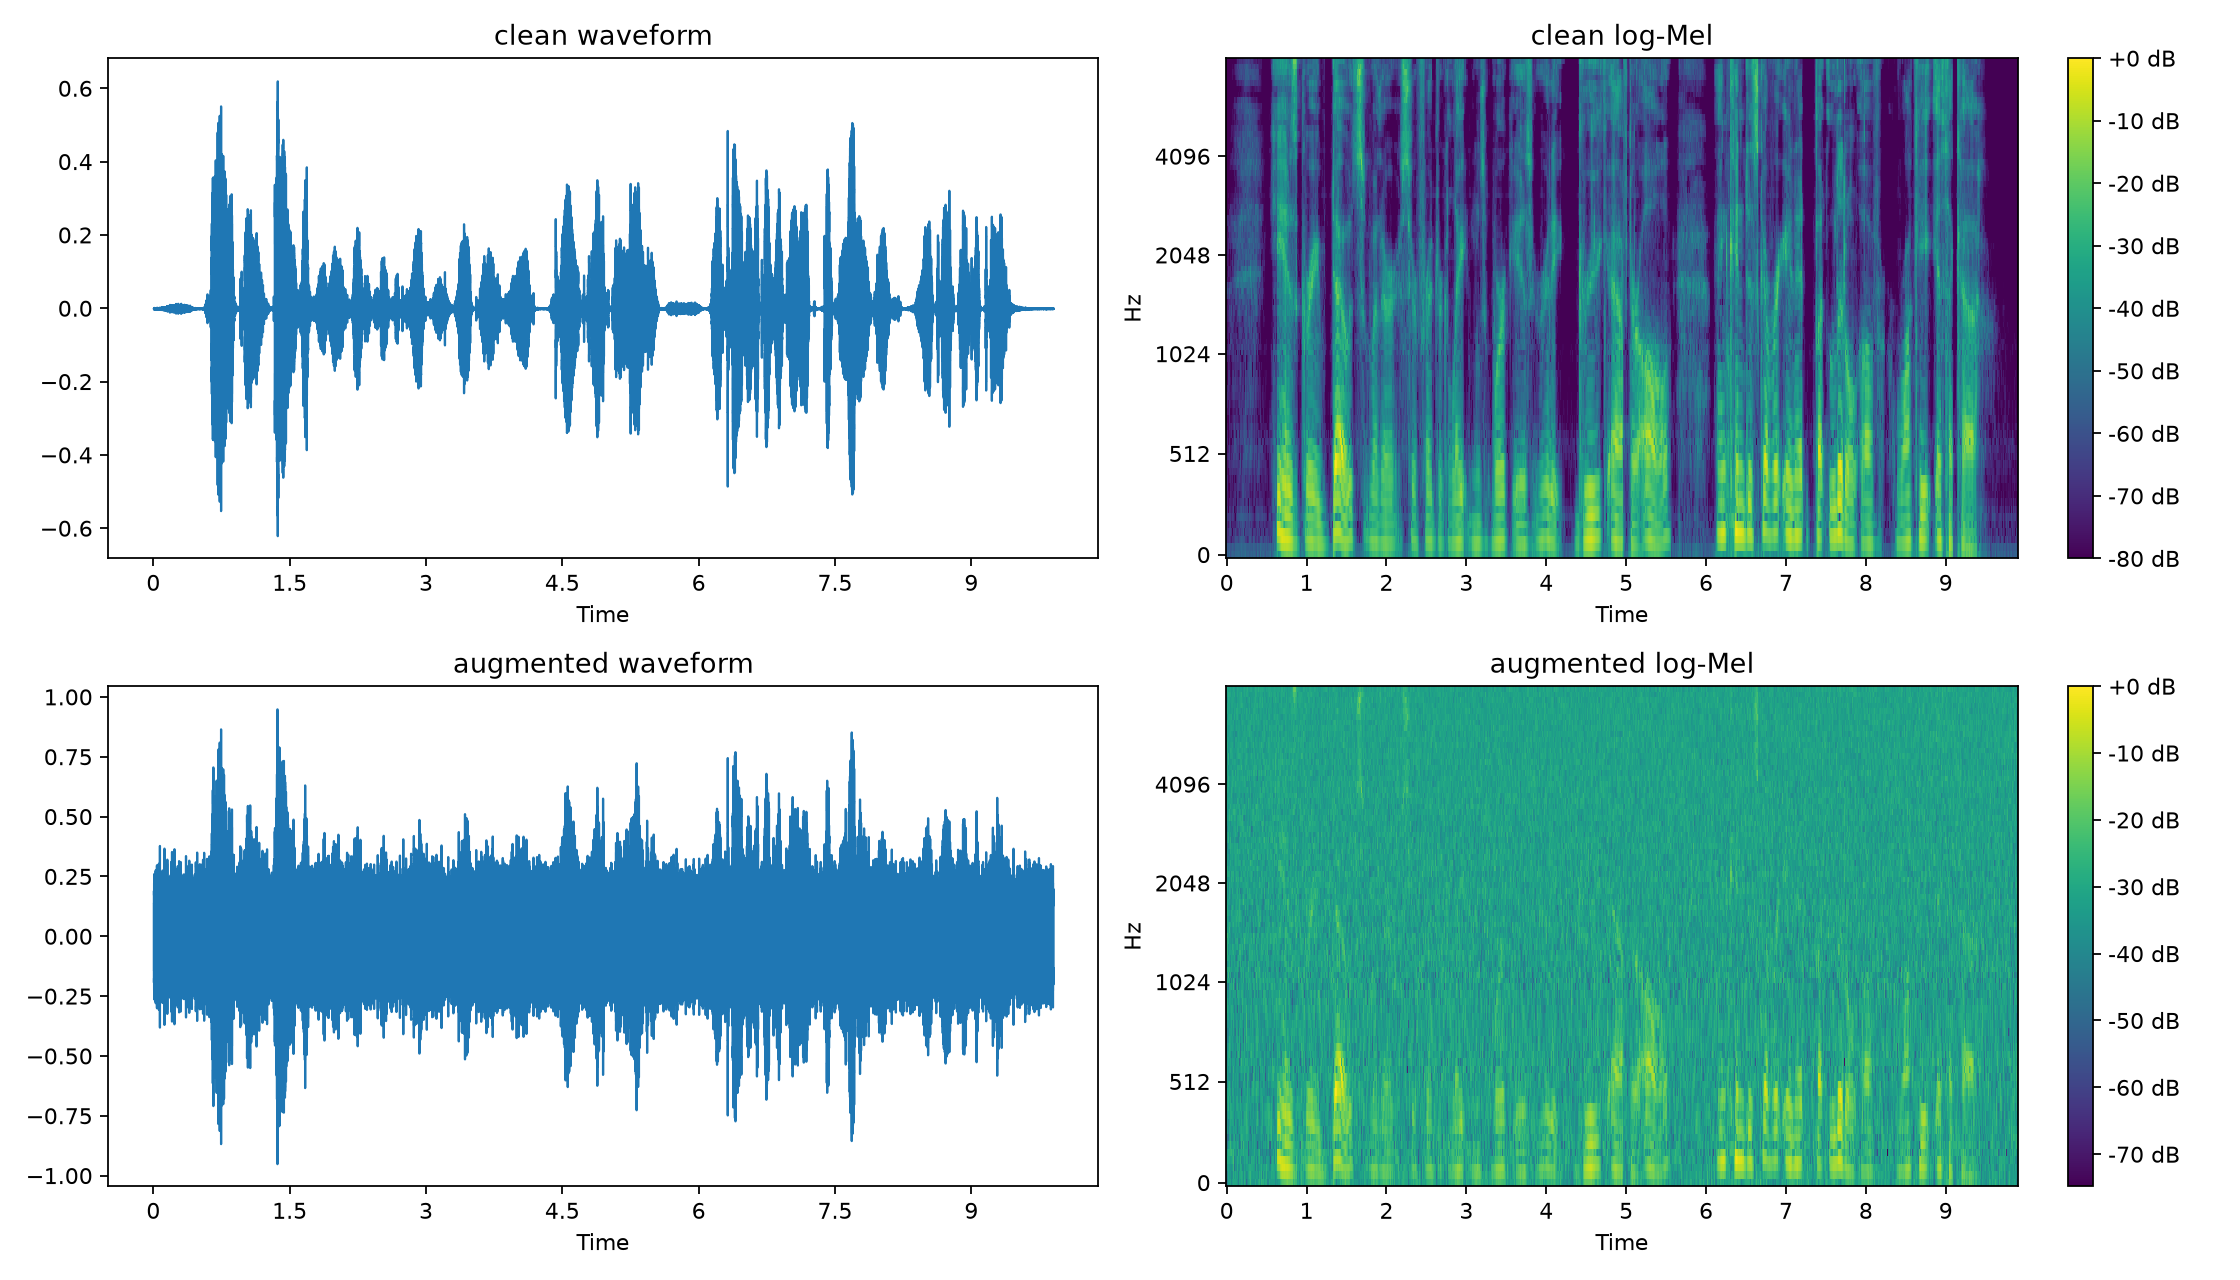

reverb_room_a


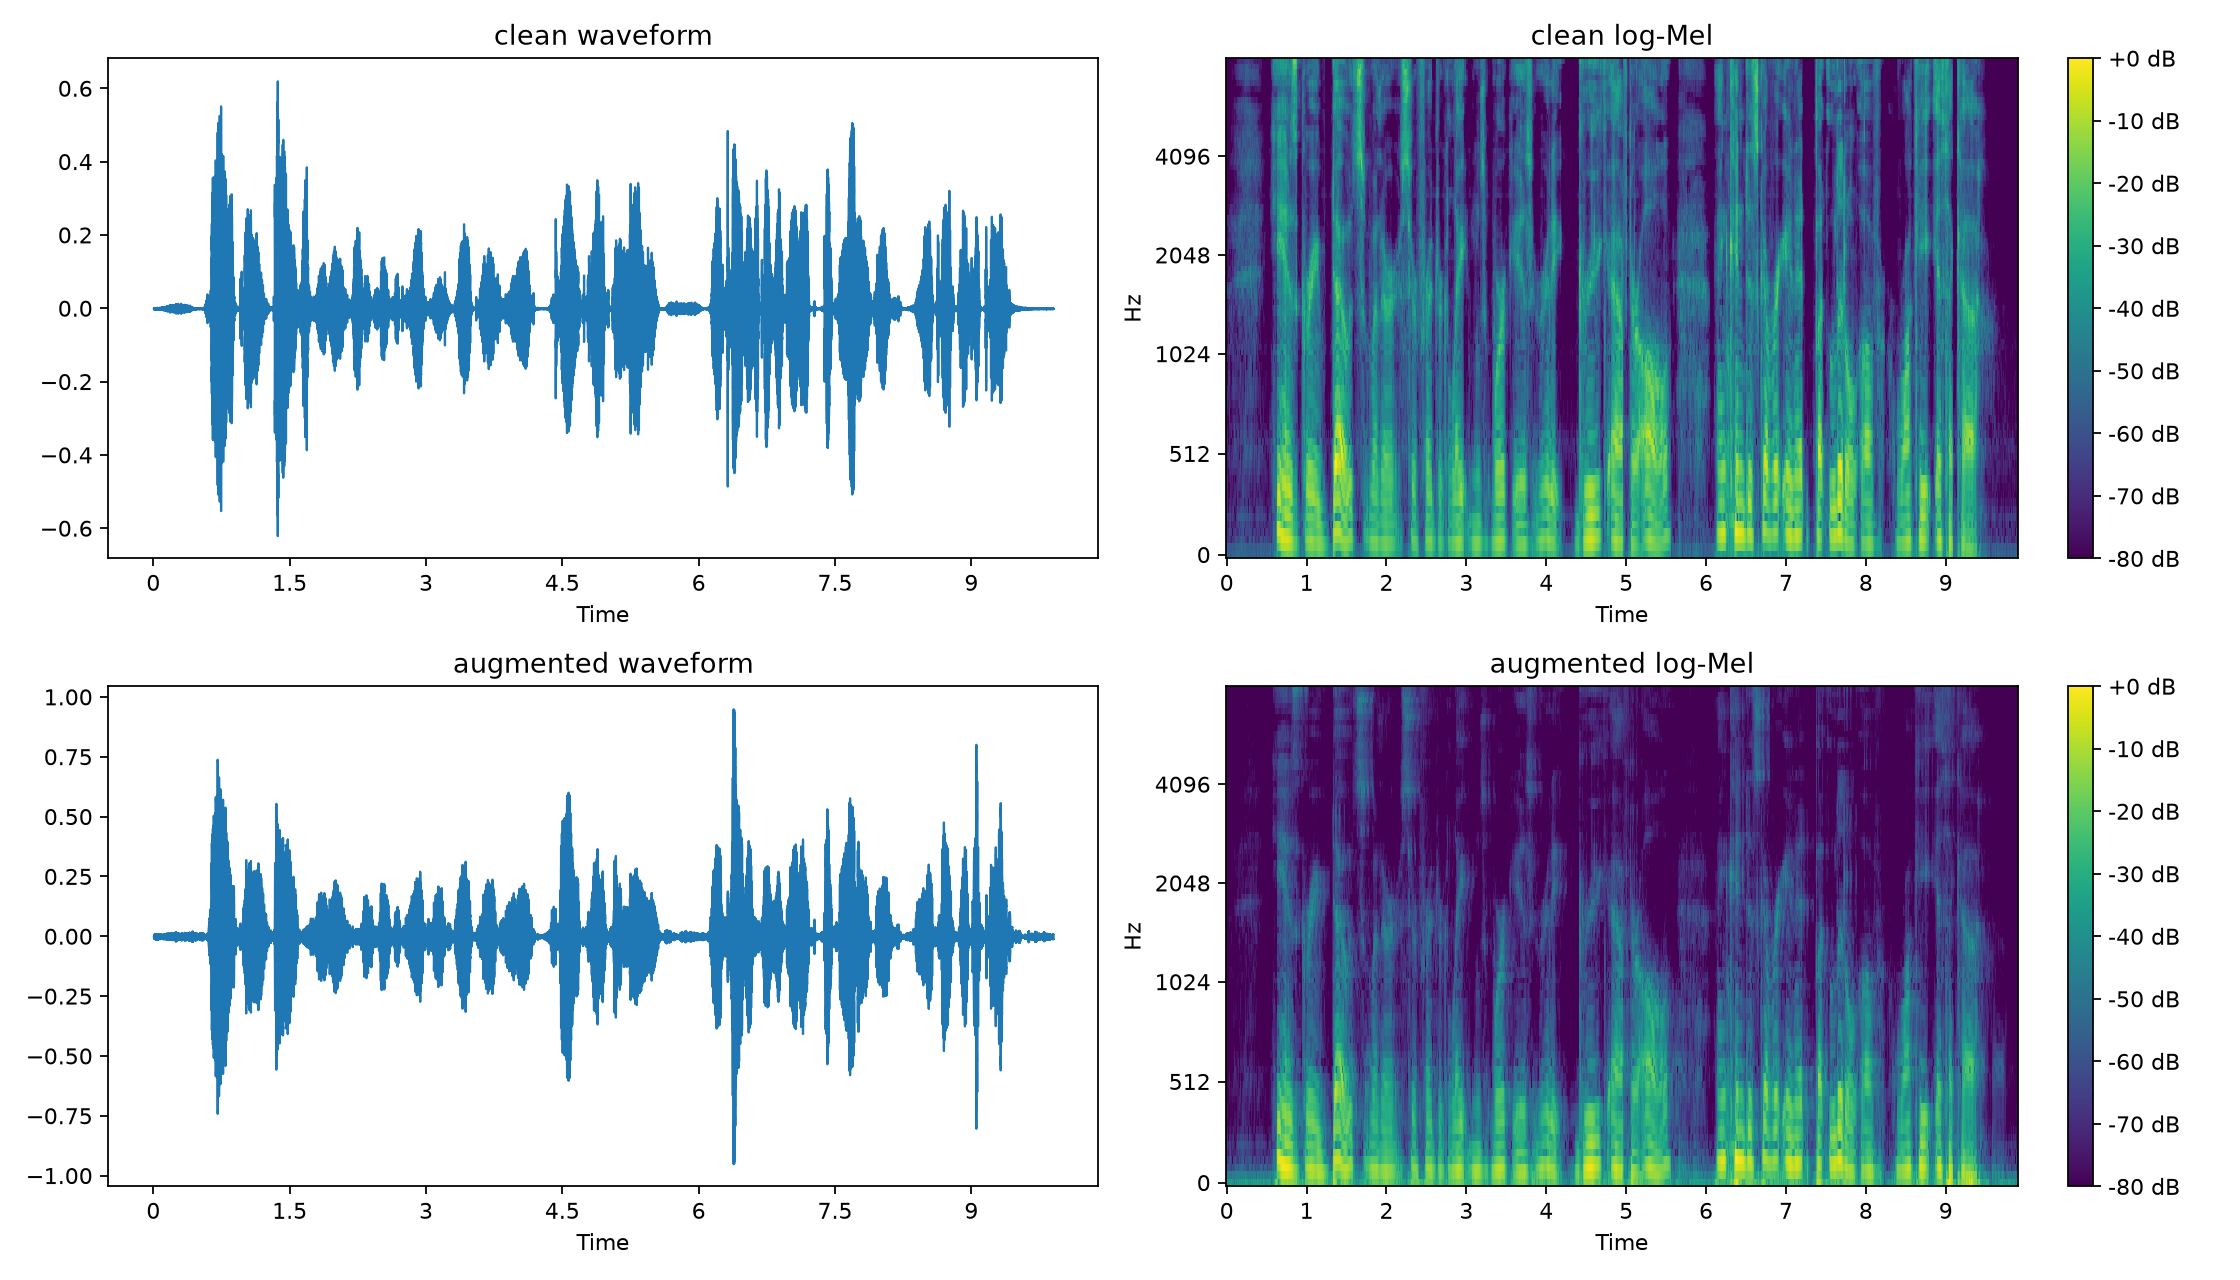

In [8]:
AUGMENTED_WAV = AUG_DIR / f"{ITEM_ID}__noise_0db.wav"

OUTPUT_FIG_DIR = FIG_DIR / "task1_noise_0db"
OUTPUT_FIG_DIR.mkdir(parents=True, exist_ok=True)

subprocess.run([
    sys.executable,
    str(PLOT_SCRIPT),
    "--clean",
    str(CLEAN_WAV),
    "--augmented",
    str(AUGMENTED_WAV),
    "--out-dir",
    str(OUTPUT_FIG_DIR),
], check=True)

print('noise_0db')
display(Image(filename=str(OUTPUT_FIG_DIR / "clean_vs_augmented.png")))

AUGMENTED_WAV = AUG_DIR / f"{ITEM_ID}__reverb_room_a.wav"

OUTPUT_FIG_DIR = FIG_DIR / "task1_reverb_room_a"
OUTPUT_FIG_DIR.mkdir(parents=True, exist_ok=True)

subprocess.run([
    sys.executable,
    str(PLOT_SCRIPT),
    "--clean",
    str(CLEAN_WAV),
    "--augmented",
    str(AUGMENTED_WAV),
    "--out-dir",
    str(OUTPUT_FIG_DIR),
], check=True)

print('reverb_room_a')
display(Image(filename=str(OUTPUT_FIG_DIR / "clean_vs_augmented.png")))

**Выводы:**

Для анализа были выбраны две аугментации:

1. `noise_0db` - аддитивный шум с SNR = 0 dB.
2. `reverb_room_a` - искусственная реверберация.

**noise_0db:**
В волновой форме исходная форма сигнала становится значительно менее различимой на фоне шума. На log-Mel спектрограмме появляется дополнительная энергия по всей временной области в широком диапазоне частот.
Шум снижает различимость исходных акустических признаков за счет наложения дополнительной энергии на полезный сигнал.

**reverb_room_a:**
Некоторые участки сигнала "сливаются", размываются во времени, на лог-мел в конце кадра заметен артефакт, как бы дублирующий предыдущий звук. 
Также на лог-мел спектрограмме заметно ослабление энергии в области высоких частот >> высокочастотные компоненты поглощаются из-за отражений.

В отличие от аддитивного шума, который добавляет постороннюю энергию и маскирует речевые признаки, реверберация изменяет структуру уже существующего речевого сигнала.

## Задание №2

Сравните аугментацию реверберацией room_a с аугментацией шумом. Какое видимое различие согласуется с временным размыванием, а не с простым аддитивным маскированием?

noise_10db


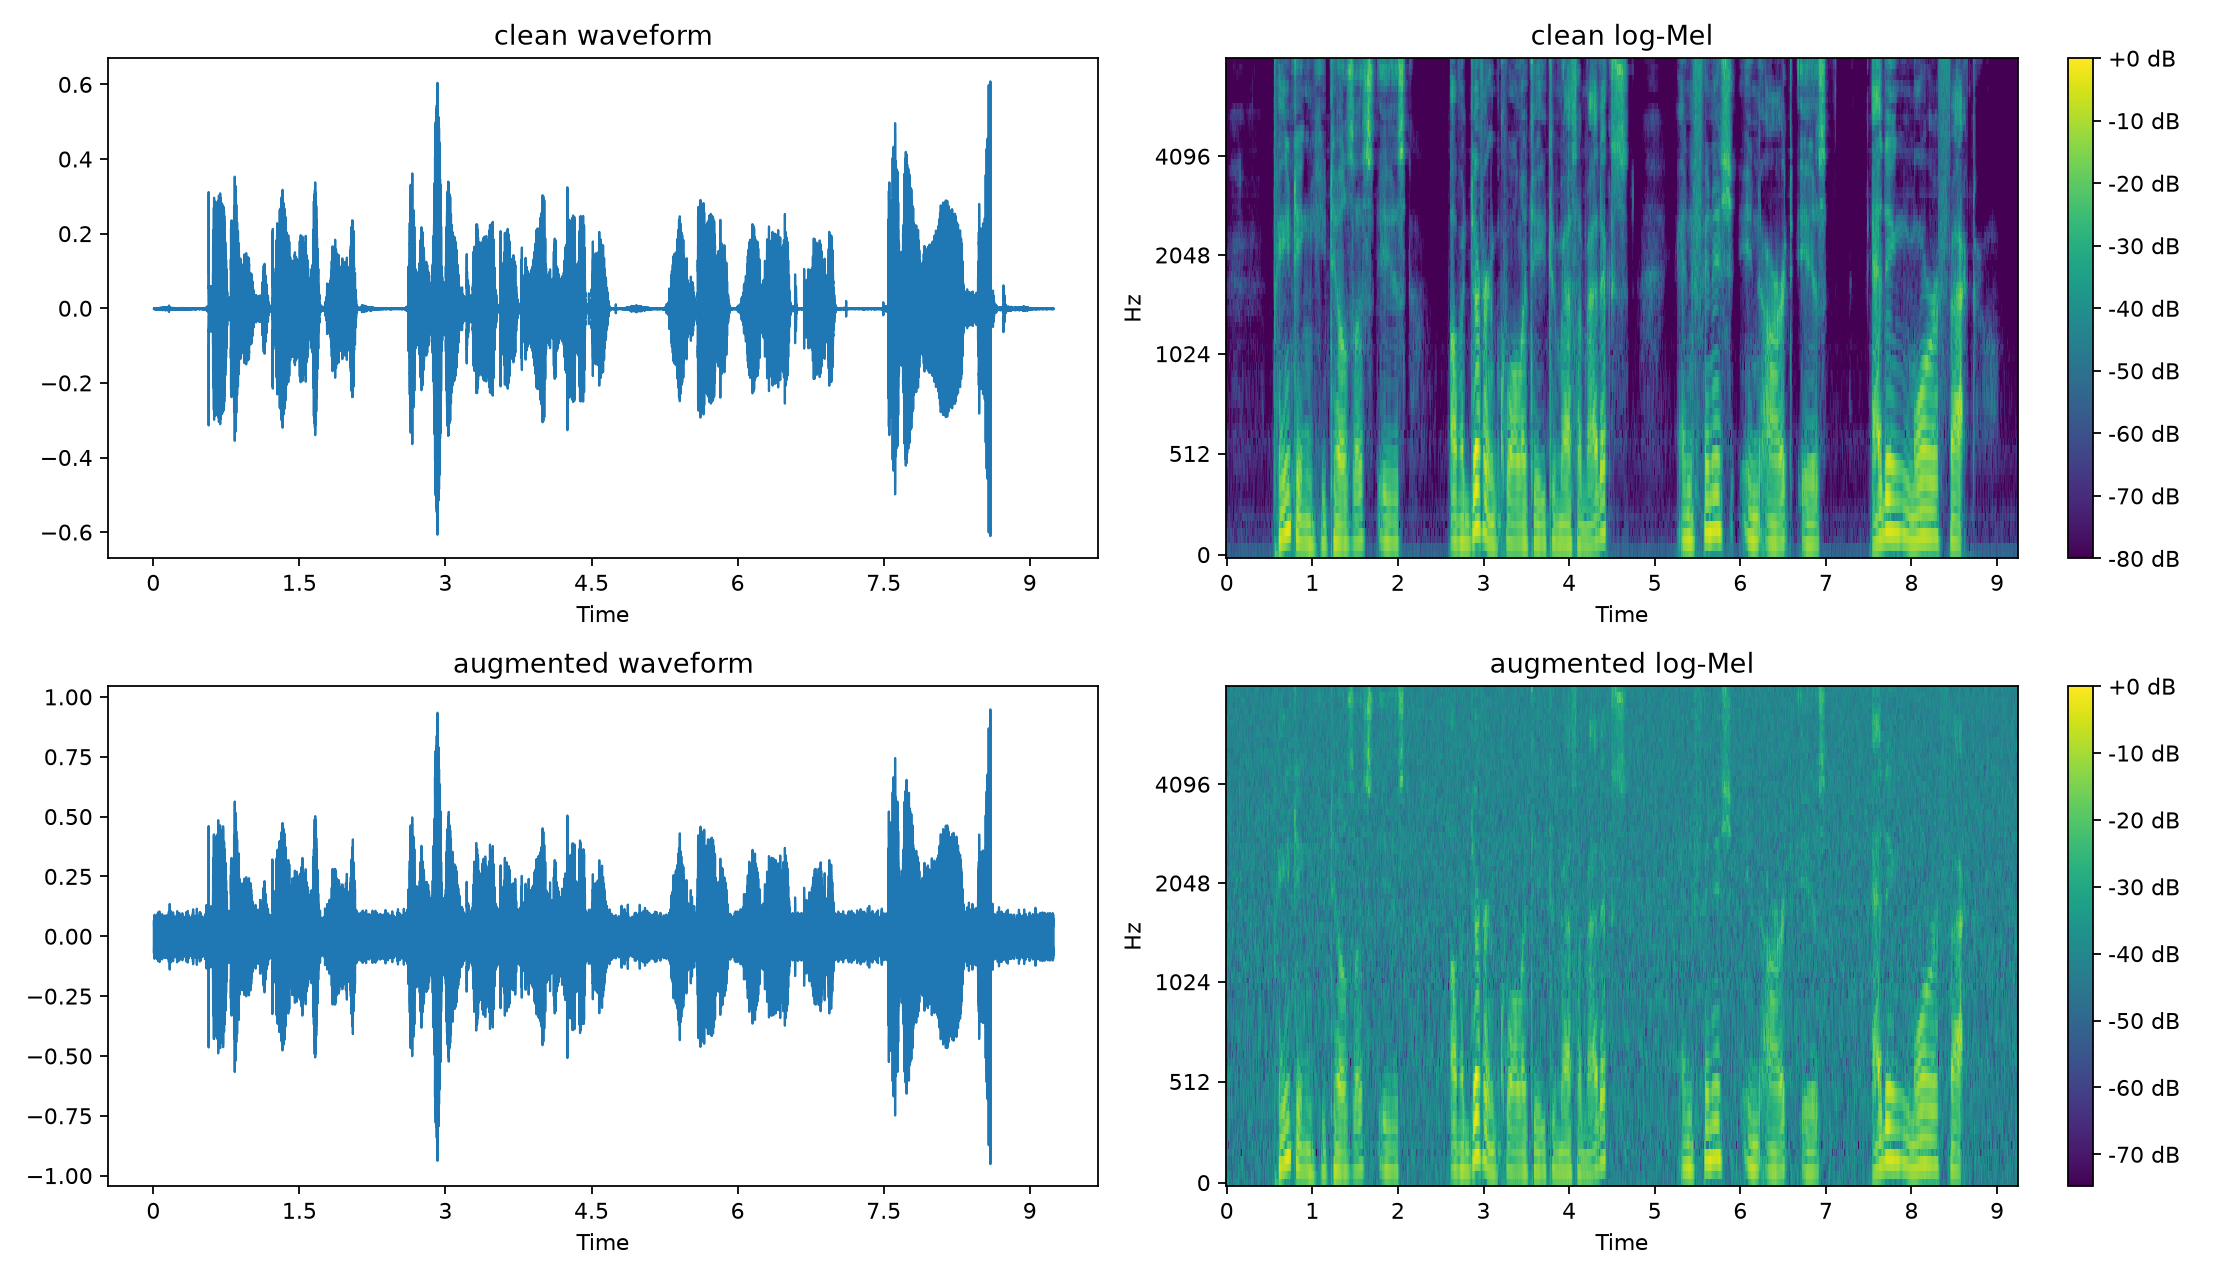

reverb_room_a


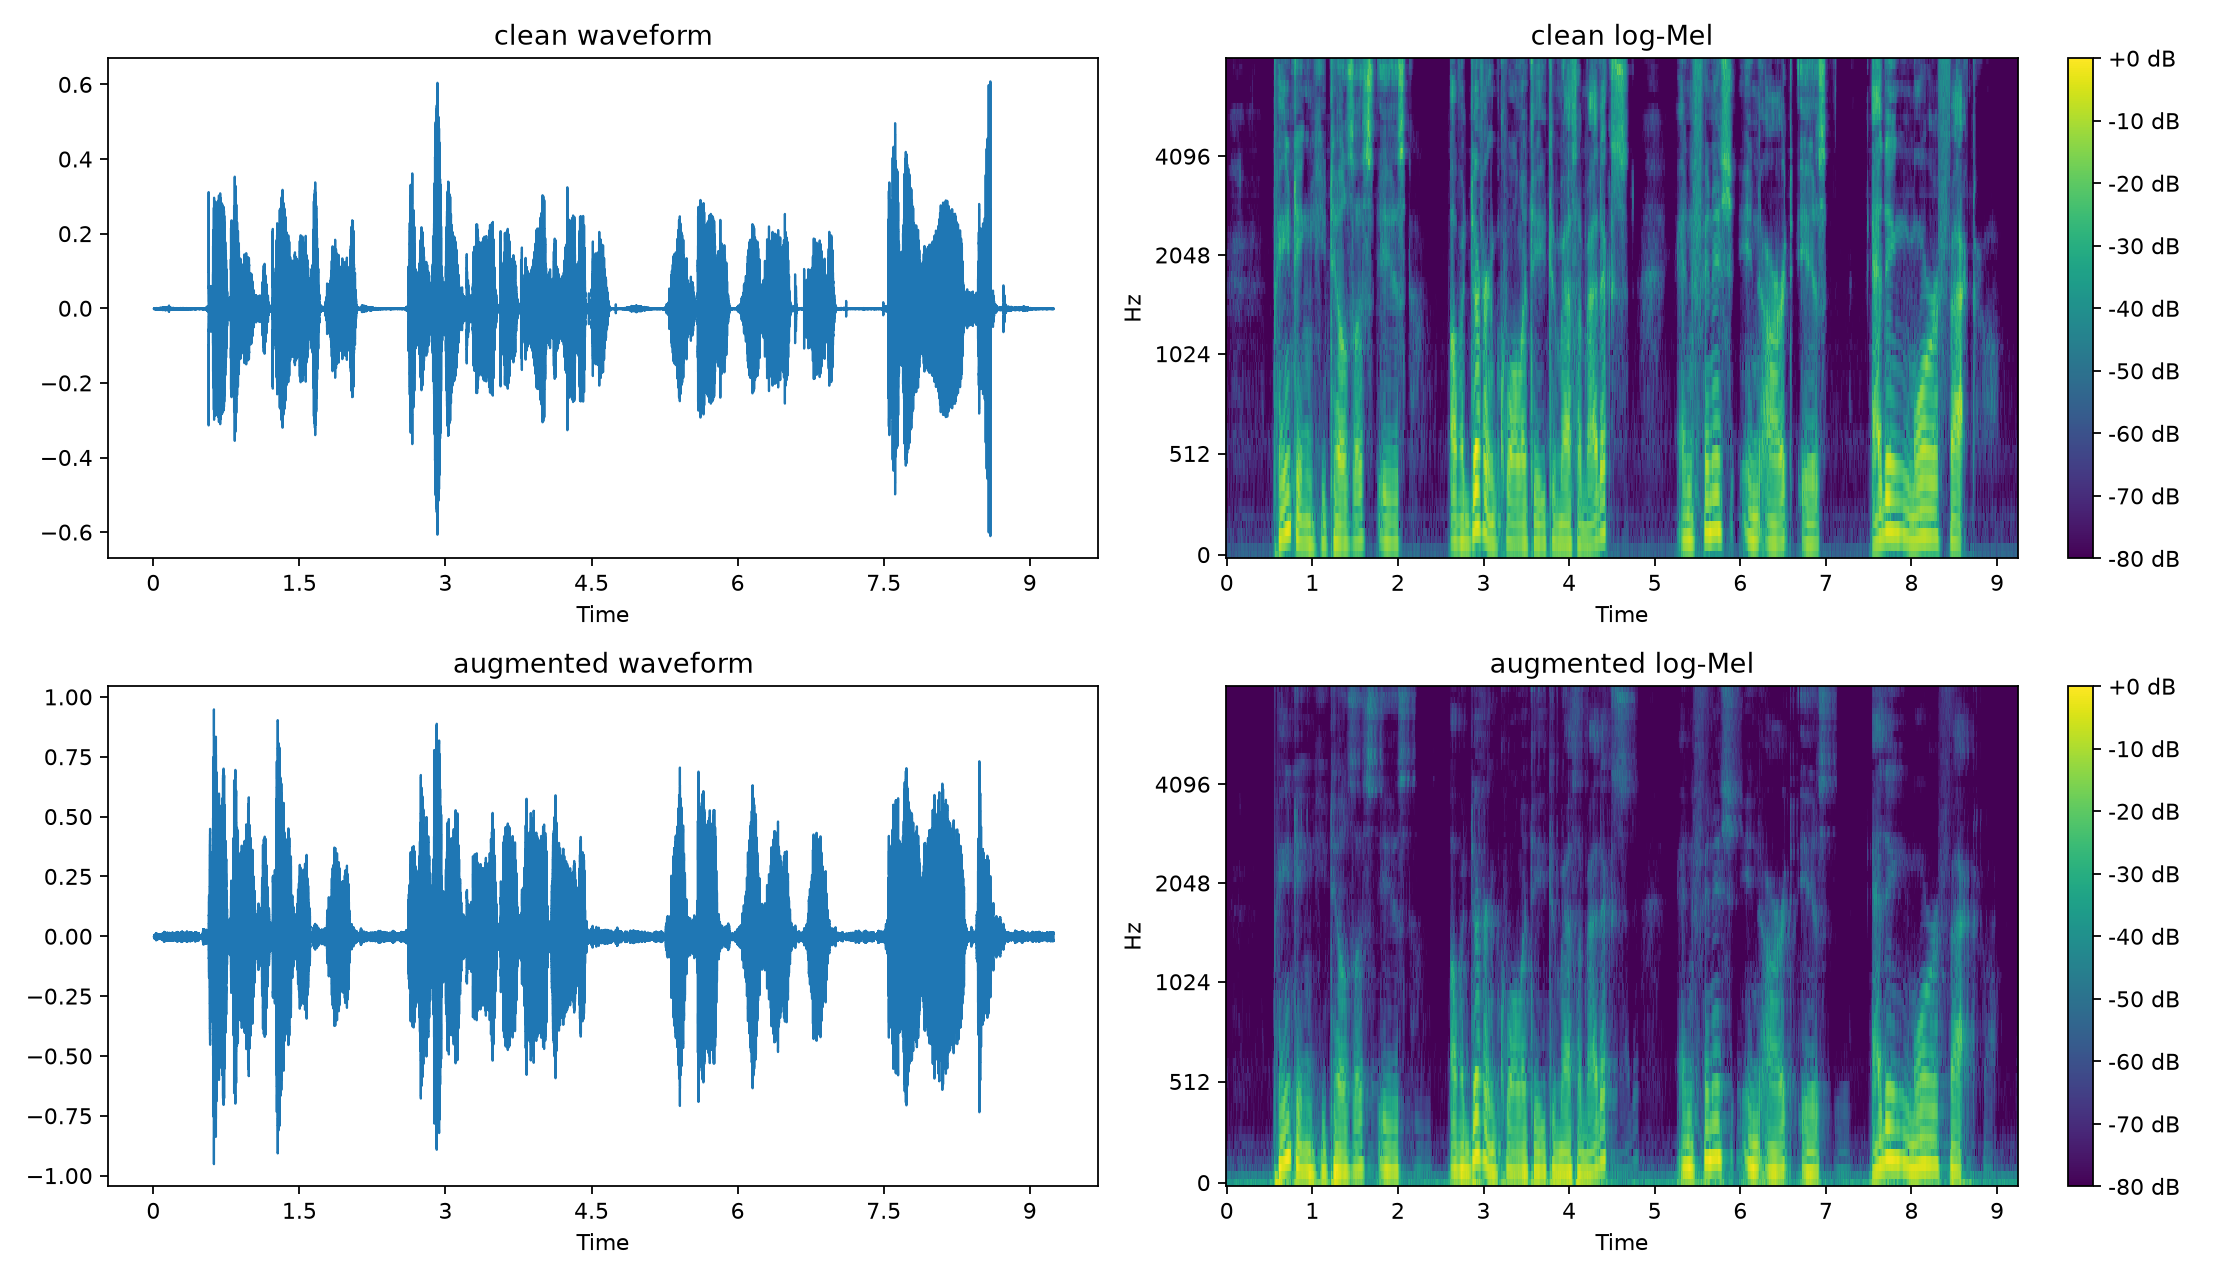

In [9]:
PLOT_SCRIPT = SCRIPTS_DIR / "plot_augmentation_features.py"
ITEM_ID = "1272-128104-0007"
CLEAN_WAV = WAV_DIR / f"{ITEM_ID}.wav"

AUGMENTED_WAV = AUG_DIR / f"{ITEM_ID}__noise_10db.wav"

OUTPUT_FIG_DIR = FIG_DIR / "task2_noise_10db"
OUTPUT_FIG_DIR.mkdir(parents=True, exist_ok=True)

subprocess.run([
    sys.executable,
    str(PLOT_SCRIPT),
    "--clean",
    str(CLEAN_WAV),
    "--augmented",
    str(AUGMENTED_WAV),
    "--out-dir",
    str(OUTPUT_FIG_DIR),
], check=True)

print('noise_10db')
display(Image(filename=str(OUTPUT_FIG_DIR / "clean_vs_augmented.png")))


AUGMENTED_WAV = AUG_DIR / f"{ITEM_ID}__reverb_room_a.wav"

OUTPUT_FIG_DIR = FIG_DIR / "task2_reverb_room_a"
OUTPUT_FIG_DIR.mkdir(parents=True, exist_ok=True)

subprocess.run([
    sys.executable,
    str(PLOT_SCRIPT),
    "--clean",
    str(CLEAN_WAV),
    "--augmented",
    str(AUGMENTED_WAV),
    "--out-dir",
    str(OUTPUT_FIG_DIR),
], check=True)

print('reverb_room_a')
display(Image(filename=str(OUTPUT_FIG_DIR / "clean_vs_augmented.png")))

**Выводы:**

При `noise_10db` к исходному сигналу добавляется шум, поэтому увеличивается фоновая энергия, и полезный сигнал теряется, но временная структура сохраняется.

При `reverb_room_a` появляются энергетические "хвосты", переходы между речью "размазываются".

Таким образом, реверберацию можно отличить от простого аддитивного шума по распространению энергии во времени.

## Задание №3

Сравните длительности аудио 0.9× и 1.1× с исходыми. Как каждый фактор влияет на длительность и почему одного изменения длительности недостаточно для предсказания как себя поведёт WER?

In [10]:
metrics = ["audio_seconds", "wer", "cer"]

duration_table = (
    per_item[per_item["condition"].isin(["clean", "speed_0.9x", "speed_1.1x"])]
    .pivot(index="item_id", columns="condition", values=metrics)
)

display(duration_table.style.format("{:.4f}"))

**Выводы:**

Изменение длительности само по себе плохо предсказывает изменение WER. Замедление на 10% увеличило длительность примерно на 11%, но средний WER практически не изменился. Ускорение на 10% уменьшило длительность примерно на 9%, а WER при этом даже снизился. Поэтому для ASR важна не столько длительность записи, а то, как изменение темпа изменяет акустические признаки речи и насколько модель устойчива к таким изменениям.

Снижение WER при 1.1× нельзя считать доказательством того, что ускорение улучшает ASR. В выборке всего 5 записей, поэтому даже одна ошибка может заметно повлиять на среднее.

## Задание №4

Какие области скрыты временными и частотными масками в specaugment_feature_only.png? Предположите, почему такая аугментация может быть полезной для обучения систем ASR?

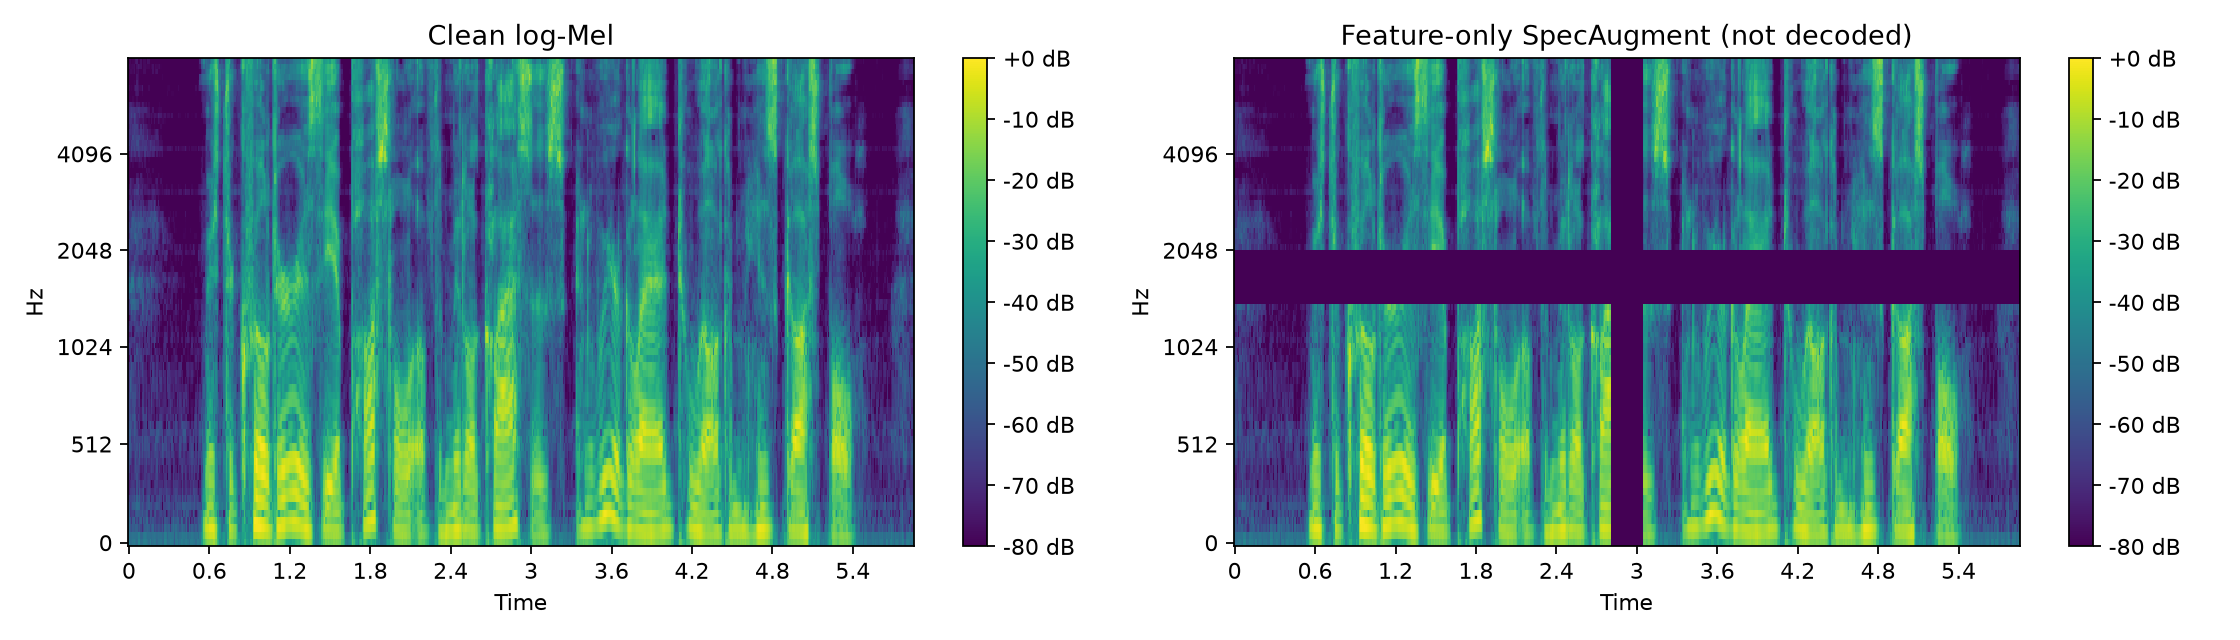

In [11]:
specaugment_img = LAB_DIR / "outputs" / "figures" / "specaugment_feature_only.png"
display(Image(filename=str(specaugment_img)))

**Выводы:**

Временная маска скрывает вертикальный участок спектрограммы,
то есть несколько последовательных временных кадров (до 24, около 240 мс при шаге 10 мс) по частотной оси. Частотная маска скрывает горизонтальный участок, то есть диапазон частот (до 10 из 80 мел-бинов) по временной оси.

Такая аугментация может быть полезной, так как если часть временной или частотной информации случайно скрывается во время обучения, модель вынуждена использовать контекст и распределенную информацию о речевом сигнале. Это может повысить устойчивость к пропускам, шуму и другим акустическим искажениям.

## Задание №5

Для одного тестового примера сравните результаты распознавания чистого сигнала с результатами двух его аугментированных вариантов. Укажите WER, CER и RTF для всех трёх аудио. Какая метрика изменяется сильнее всего в выбранном сравнении? Как думаете, почему?

In [13]:
ITEM_ID = "1272-128104-0001"

task5 = per_item[
    (per_item["item_id"] == ITEM_ID) &
    (per_item["condition"].isin([
        "clean",
        "noise_10db",
        "reverb_room_a"
    ]))
][
    [
        "condition",
        "reference_raw",
        "hypothesis_raw",
        "wer",
        "cer",
        "rtf",
    ]
].copy()

display(task5.style.hide(axis='index').format({"wer": "{:.4f}", "cer": "{:.4f}", "rtf": "{:.4f}"}))

condition,reference_raw,hypothesis_raw,wer,cer,rtf
clean,NOR IS MISTER QUILTER'S MANNER LESS INTERESTING THAN HIS MATTER,Nor is Mr. Quilter's manner less interesting than his matter.,0.1000,0.0635,0.0907
noise_10db,NOR IS MISTER QUILTER'S MANNER LESS INTERESTING THAN HIS MATTER,Nor is Mr. Colter's matter less interesting than his matter.,0.3000,0.1429,0.0900
reverb_room_a,NOR IS MISTER QUILTER'S MANNER LESS INTERESTING THAN HIS MATTER,Nor is Mr. Quilter's matter less interesting than his matter.,0.2000,0.0952,0.1185


**Выводы:**

В выбранном примере сильнее всего меняется WER: при добавлении шума 10 дБ он увеличился с 0.10 до 0.30. CER тоже вырос - с 0.0635 до 0.1429. При реверберации WER увеличился с 0.10 до 0.20, то есть в два раза относительно чистого сигнала. CER вырос, но менее значительно - с 0.0635 до 0.0952.

WER оказывается более чувствительным, потому что считает ошибки на уровне слов, поэтому даже небольшое искажение слова может заметно увеличить WER при относительно небольшом изменении CER, который учитывает только изменившиеся символы.

## Задание №6

Определите вариант аугментации с наибольшим агрегированным mean_wer в aggregate_results.csv. Укажите его имя, агрегированные mean_wer, mean_cer и сравнение текстовок для одного тестового примера с этой аугментацией. Как вы думаете, почему такая аугментация сильнее всего сказывается на работе ASR модели?

In [33]:
worst_row = aggregate.loc[aggregate["mean_wer"].idxmax()]

print("Худшая аугментация:", worst_row["condition"])
print()

print("mean WER:", f"{worst_row['mean_wer']:.6f}")
print("mean CER:", f"{worst_row['mean_cer']:.6f}")

worst_condition = worst_row["condition"]
worst_item = (per_item[per_item["condition"] == worst_condition].sort_values("wer", ascending=False).iloc[0])

print("\nХудший item_id:", worst_item["item_id"])

clean_example = per_item[
    (per_item["item_id"] == worst_item["item_id"]) &
    (per_item["condition"] == "clean")
].iloc[0]

aug_example = per_item[
    (per_item["item_id"] == worst_item["item_id"]) &
    (per_item["condition"] == worst_condition)
].iloc[0]

print("\nReference:")
print(clean_example["reference_raw"])

print("\nClean:")
print(clean_example["hypothesis_raw"])

print("\nnoise_0db:")
print(aug_example["hypothesis_raw"])

print("\nМетрики:")

print(
    f"Clean: WER={clean_example['wer']:.4f}, "
    f"CER={clean_example['cer']:.4f}"
)

print(
    f"{worst_condition}: "
    f"WER={aug_example['wer']:.4f}, "
    f"CER={aug_example['cer']:.4f}"
)

Худшая аугментация: noise_0db

mean WER: 0.701564
mean CER: 0.394072

Худший item_id: 1272-128104-0006

Reference:
ON THE GENERAL PRINCIPLES OF ART MISTER QUILTER WRITES WITH EQUAL LUCIDITY

Clean:
On the general principles of art, Mr. Krilter writes with equal lucidity.

noise_0db:
and the general principles of art to make the trophy right to the people in this city team.

Метрики:
Clean: WER=0.1667, CER=0.0811
noise_0db: WER=1.0833, CER=0.5946


**Выводы:**

При SNR = 0 dB мощность шума сравнима с мощностью
полезного сигнала, поэтому акустические признаки речи сильно маскируются, что приводит к большому количеству ошибок распознавания. Ошибки могут затрагивать не только отдельные символы, но и целые слова и фрагменты предложения. 

## Задание №7

Найдите такой тип аугментации, для которого WER и CER сигнализируют о разном уровне влияния на систему ASR (скажем WER деградирует значительно, но CER увеличивается не очень сильно). Рассмотрите текстовки, предположите, почему наблюдается такое поведение?

In [86]:
agg = aggregate.set_index("condition")
base = agg.loc["clean"]
t = pd.DataFrame({
    "mean_wer": agg.mean_wer,
    "mean_cer": agg.mean_cer,
    "WER, % к clean": (agg.mean_wer / base.mean_wer - 1) * 100,
    "CER, % к clean": (agg.mean_cer / base.mean_cer - 1) * 100,
}).drop("clean")

bad = t[(t["WER, % к clean"] > 0) & (t["CER, % к clean"] > 0)].copy()
bad["WER-рост / CER-рост"] = bad["WER, % к clean"] / bad["CER, % к clean"]
bad = bad.sort_values("WER-рост / CER-рост", ascending=False)
display(bad.round(3))

best = bad.index[0]
print(f"Сильнее всего расходятся WER и CER в {best} "
      f"(WER вырос на {bad.loc[best, 'WER, % к clean']:.0f}%, CER на {bad.loc[best, 'CER, % к clean']:.0f}%)")

,mean_wer,mean_cer,"WER, % к clean","CER, % к clean",WER-рост / CER-рост
condition,,,,,
reverb_room_a,0.112,0.055,33.747,9.694,3.481
noise_20db,0.129,0.070,53.598,40.117,1.336
noise_10db,0.149,0.082,77.420,63.637,1.217
noise_0db,0.702,0.394,735.613,688.475,1.068


Сильнее всего расходятся WER и CER в reverb_room_a (WER вырос на 34%, CER на 10%)


In [91]:
sel = per_item[per_item.condition.isin(["clean", best])].copy()

changed = sel.groupby("item_id").hypothesis_normalized.nunique() > 1
sel = sel[sel.item_id.map(changed)]

ref = sel[sel.condition == "clean"].copy()
ref["condition"] = "эталон"
ref["hypothesis_raw"] = ref["reference_raw"]
ref[["wer", "cer"]] = float("nan")

order = {"эталон": 0, "clean": 1, best: 2}
table = (
    pd.concat([ref, sel])
    .assign(_order=lambda d: d.condition.map(order))
    .sort_values(["item_id", "_order"])
)
table["item_id"] = table["item_id"].str[-4:]
table = (
    table.set_index(["item_id", "condition"])[["wer", "cer", "hypothesis_raw"]]
    .rename(columns={"hypothesis_raw": "text"})
)

display(
    table.reset_index()
    .style.hide(axis='index')
    .format({"wer": "{:.3f}", "cer": "{:.3f}"}, na_rep="")
    .set_properties(subset=["text"], **{"text-align": "left"})
)

item_id,condition,wer,cer,text
0001,эталон,,,NOR IS MISTER QUILTER'S MANNER LESS INTERESTING THAN HIS MATTER
0001,clean,0.100,0.063,Nor is Mr. Quilter's manner less interesting than his matter.
0001,reverb_room_a,0.200,0.095,Nor is Mr. Quilter's matter less interesting than his matter.
0003,эталон,,,HE HAS GRAVE DOUBTS WHETHER SIR FREDERICK LEIGHTON'S WORK IS REALLY GREEK AFTER ALL AND CAN DISCOVER IN IT BUT LITTLE OF ROCKY ITHACA
0003,clean,0.042,0.030,"He has grave doubts whether Sir Frederick Layton's work is really Greek after all, and can discover in it but little of rocky Ithaca."
0003,reverb_room_a,0.083,0.023,"He has grave doubts whether Sir Frederick Leighton's work is really Greek after all, and can discover in it but little of wonky ithaka."


**Выводы:**

Сильнее всего WER и CER расходятся для `reverb_room_a`. По сравнению с чистым сигналом средний WER вырос с 0,084 до 0,112 (+34%), а средний CER с 0,050 до 0,055 (+10%). У шума такого расхождения нет.

В записи 0001 реверберация дает одну новую ошибку, manner → matter: WER вырос вдвое (0,100 → 0,200), а CER лишь с 0,063 до 0,095, потому что слова отличаются двумя буквами. В записи 0003 слов-ошибок стало больше, но CER даже снизился (0,030 → 0,023): исчезла ошибка Layton's, зато появились rocky → wonky и ithaca → ithaka, которые отличаются тремя символами в сумме. WER засчитывает слово ошибочным целиком, а CER учитывает только число неверных букв, поэтому несколько почти верных слов сильно повышают WER и почти не меняют CER.

Реверберация размазывает короткие переходы между звуками, поэтому похожие согласные путаются, а декодер подставляет "привычное" слово. Это вывод по двум записям: остальные три записи (0000, 0006, 0007) реверберация не изменила.

## Задание №8

Для идентичной ошибки/ошибок распознавания при разных типах аугментации приведите эталон и гипотезу (или их фрагменты). Является ли правдоподобным объяснением акустическое маскирование, временное размывание, сегментация/тайминг или предпочтение декодера/языковой модели? Укажите, какие у вас есть предположения, относительно таких ошибок распознавания.

In [74]:
repeated_errors = []

for item_id, group in per_item.groupby("item_id"):
    reference = group.iloc[0]["reference_normalized"].split()

    for _, row in group.iterrows():
        hypothesis = row["hypothesis_normalized"].split()

        for i in range(min(len(reference), len(hypothesis))):
            if reference[i] != hypothesis[i]:
                repeated_errors.append({
                    "item_id": item_id,
                    "position": i,
                    "reference_word": reference[i],
                    "hypothesis_word": hypothesis[i],
                    "condition": row["condition"]
                })

repeated_errors = pd.DataFrame(repeated_errors)

repeated_errors = (
    repeated_errors
    .groupby([
        "item_id",
        "position",
        "reference_word"
    ])
    .agg(
        hypothesis_words=("hypothesis_word", list),
        conditions=("condition", list),
        count=("condition", "count")
    )
    .reset_index()
)

repeated_errors = (
    repeated_errors[
        repeated_errors["count"] >= 2
    ]
    .sort_values(
        ["item_id", "count"],
        ascending=[True, False]
    )
    .style.hide(axis='index')
)

repeated_errors

item_id,position,reference_word,hypothesis_words,conditions,count
1272-128104-0000,0,mister,"['mr', 'mr', 'mr', 'mr', 'mr', 'mr', 'mr']","['clean', 'noise_20db', 'noise_10db', 'noise_0db', 'reverb_room_a', 'speed_0.9x', 'speed_1.1x']",7
1272-128104-0001,2,mister,"['mr', 'mr', 'mr', ""quotley's"", 'mr', 'mr', 'mr']","['clean', 'noise_20db', 'noise_10db', 'noise_0db', 'reverb_room_a', 'speed_0.9x', 'speed_1.1x']",7
1272-128104-0001,3,quilter's,"[""coulter's"", ""colter's"", 'now']","['noise_20db', 'noise_10db', 'noise_0db']",3
1272-128104-0001,4,manner,"['matter', 'less', 'matter']","['noise_10db', 'noise_0db', 'reverb_room_a']",3
1272-128104-0003,7,leighton's,"[""layton's"", ""layton's"", ""he's"", ""layton's"", ""layton's""]","['clean', 'noise_20db', 'noise_0db', 'speed_0.9x', 'speed_1.1x']",5
1272-128104-0003,22,rocky,"['wonky', 'wonky', 'in', 'wonky']","['noise_20db', 'noise_10db', 'noise_0db', 'reverb_room_a']",4
1272-128104-0003,23,ithaca,"['ichaka', 'essaka', 'it', 'ithaka']","['noise_20db', 'noise_10db', 'noise_0db', 'reverb_room_a']",4
1272-128104-0003,2,grave,"['great', 'great', 'great']","['noise_20db', 'noise_10db', 'noise_0db']",3
1272-128104-0003,11,greek,"['great', 'him']","['noise_10db', 'noise_0db']",2
1272-128104-0006,6,mister,"['mr', 'mr', 'mr', 'to', 'mr', 'mr', 'mr']","['clean', 'noise_20db', 'noise_10db', 'noise_0db', 'reverb_room_a', 'speed_0.9x', 'speed_1.1x']",7


**Выводы:**

Повторяющиеся ошибки можно разделить на два типа.
1) Ошибки, которые присутствуют уже на чистом сигнале, например mister → mr, quilter → krilter и fact → effect. Они, вероятно, связаны не с конкретным акустическим искажением, а с особенностями самой модели и декодирования. Например, mister → mr может быть связано с предпочтением декодера.
2) Ошибки, которые появляются или усиливаются при акустических искажениях. Например, manner → matter появляется при noise_10db, noise_0db и reverb_room_a. В случае реверберации границы между фонемами становятся менее четкими, поэтому близкие по звучанию согласные могут путаться. При шуме некоторые звуки также теряются в добавленном энергетическом фоне.

Стоит предположить сочетание акустической ошибки и последующего выбора декодером наиболее вероятного слова.

## Задание №9

Как вы думаете, всегда ли более высокий WER в нашем бенчмарке, есть индикатор того, что такая аугментация - универсальная ASR? Назовите два фактора в этой лабораторной работе, которые не позволяют сделать такой вывод.

In [75]:
display(
    aggregate[
        [
            "condition",
            "mean_wer",
            "mean_cer",
            "mean_rtf"
        ]
    ].style.format({
        "mean_wer": "{:.4f}",
        "mean_cer": "{:.4f}",
        "mean_rtf": "{:.4f}",
    })
)

,condition,mean_wer,mean_cer,mean_rtf
0,clean,0.0840,0.0500,0.0916
1,noise_0db,0.7016,0.3941,0.1663
2,noise_10db,0.1490,0.0818,0.0986
3,noise_20db,0.1290,0.0700,0.0904
4,reverb_room_a,0.1123,0.0548,0.1085
5,speed_0.9x,0.0840,0.0480,0.0952
6,speed_1.1x,0.0673,0.0446,0.1086


In [85]:
w = per_item.pivot(index="item_id", columns="condition", values="wer")
changed = w[w["speed_1.1x"] != w["clean"]][["clean", "speed_1.1x"]]
print("Записи, где 1.1x отличается от clean по WER (из-за этого mean_wer 0.067 < 0.084):")
display(changed.round(3))

item_id = "1272-128104-0006"
condition = "clean"

example = per_item[
    (per_item["item_id"] == item_id) &
    (per_item["condition"] == condition)
].iloc[0]

print("REFERENCE:")
print(example["reference_normalized"])
print("\nHYPOTHESIS_clean:")
print(example["hypothesis_normalized"])

item_id = "1272-128104-0006"
condition = "speed_1.1x"

example1 = per_item[
    (per_item["item_id"] == item_id) &
    (per_item["condition"] == condition)
].iloc[0]

print("\nHYPOTHESIS_speed_1.1x:")
print(example1["hypothesis_normalized"])

print("\nЧистый сигнал: эталон и гипотеза после нормализации")
display(per_item[per_item.condition == "clean"][["item_id", "reference_normalized", "hypothesis_normalized", "wer"]].reset_index(drop=True).style.hide(axis = "index"))

Записи, где 1.1x отличается от clean по WER (из-за этого mean_wer 0.067 < 0.084):


condition,clean,speed_1.1x
item_id,,
1272-128104-0006,0.167,0.083


REFERENCE:
on the general principles of art mister quilter writes with equal lucidity

HYPOTHESIS_clean:
on the general principles of art mr krilter writes with equal lucidity

HYPOTHESIS_speed_1.1x:
on the general principles of art mr quilter writes with equal lucidity

Чистый сигнал: эталон и гипотеза после нормализации


item_id,reference_normalized,hypothesis_normalized,wer
1272-128104-0000,mister quilter is the apostle of the middle classes and we are glad to welcome his gospel,mr quilter is the apostle of the middle classes and we are glad to welcome his gospel,0.058824
1272-128104-0001,nor is mister quilter's manner less interesting than his matter,nor is mr quilter's manner less interesting than his matter,0.100000
1272-128104-0003,he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca,he has grave doubts whether sir frederick layton's work is really greek after all and can discover in it but little of rocky ithaca,0.041667
1272-128104-0006,on the general principles of art mister quilter writes with equal lucidity,on the general principles of art mr krilter writes with equal lucidity,0.166667
1272-128104-0007,painting he tells us is of a different quality to mathematics and finish in art is adding more fact,painting he tells us is of a different quality to mathematics and finish in art is adding more effect,0.052632


**Выводы:**

Более высокий WER в данном эксперименте показывает то, что конкретная аугментация сильнее ухудшила работу конкретной модели на данном тестовом наборе. Он не означает, что эта аугментация является универсально плохой для ASR и точно не говорит, что ее не следует использовать при обучении.
Во-первых, выборка очень маленькая: всего 5 записей, 82 слова, одна модель tiny.en, один шум и одна импульсная характеристика помещения. Отдельные ошибки могут существенно менять средний WER.
Во-вторых, в эксперименте измеряется устойчивость уже обученной модели, а не эффективность аугментации как метода обучения. Например, высокий WER на шуме 0 dB показывает, что текущая модель плохо переносит такое искажение, но не показывает, поможет ли обучение на подобных зашумленных данных сделать модель более устойчивой.